<a href="https://colab.research.google.com/github/fin-machiavelli/lab3-regression/blob/main/%D0%9B%D0%91%203_%D0%94%D0%B7%D1%8E%D0%B1%D0%B0%D0%BD%D1%87%D1%83%D0%BA_%D0%A4%D0%86%D0%A2_3_12" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")




## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")




### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
!pip install -q kagglehub

import os
import kagglehub

path = kagglehub.dataset_download("prokshitha/home-value-insights")
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
print("Файли у датасеті:", csv_files)

df = pd.read_csv(os.path.join(path, csv_files[0]))
print("Розмір:", df.shape)





Using Colab cache for faster access to the 'home-value-insights' dataset.
Файли у датасеті: ['house_price_regression_dataset.csv']
Розмір: (1000, 8)


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
display(df.head())
print()
df.info()




,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.600,0,5,"262,382.852"
1,4272,3,3,2016,4.753,1,6,"985,260.854"
2,3592,1,2,2016,3.635,0,9,"777,977.390"
3,966,1,2,1977,2.731,1,8,"229,698.919"
4,4926,2,1,1993,4.699,0,8,"1,041,740.859"



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
print("Кількість дублікатів:", df.duplicated().sum())




Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
print(df.isnull().sum())
print("\nУсього пропусків:", df.isnull().sum().sum())




Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

Усього пропусків: 0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
df.describe().T




,count,mean,std,min,25%,50%,75%,max
Square_Footage,"1,000.000","2,815.422","1,255.515",503.000,"1,749.500","2,862.500","3,849.500","4,999.000"
Num_Bedrooms,"1,000.000",2.990,1.428,1.000,2.000,3.000,4.000,5.000
Num_Bathrooms,"1,000.000",1.973,0.820,1.000,1.000,2.000,3.000,3.000
Year_Built,"1,000.000","1,986.550",20.633,"1,950.000","1,969.000","1,986.000","2,004.250","2,022.000"
Lot_Size,"1,000.000",2.778,1.298,0.506,1.666,2.810,3.923,4.989
Garage_Size,"1,000.000",1.022,0.815,0.000,0.000,1.000,2.000,2.000
Neighborhood_Quality,"1,000.000",5.615,2.887,1.000,3.000,6.000,8.000,10.000
House_Price,"1,000.000","618,861.019","253,568.058","111,626.853","401,648.229","628,267.291","827,141.278","1,108,236.836"


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
df["Neighborhood_Quality"].value_counts().sort_index()




,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

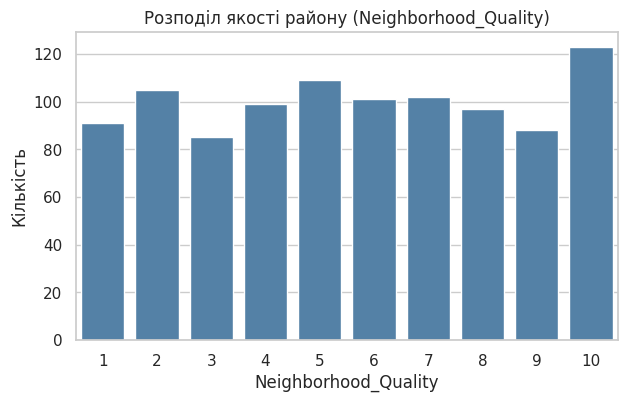

In [9]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Neighborhood_Quality", color="steelblue")
plt.title("Розподіл якості району (Neighborhood_Quality)")
plt.xlabel("Neighborhood_Quality")
plt.ylabel("Кількість")
plt.show()





### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [10]:
df["Num_Bathrooms"].value_counts().sort_index()





,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

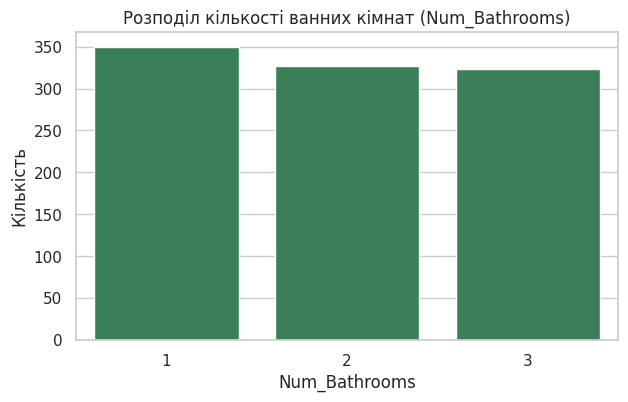

In [11]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Num_Bathrooms", color="seagreen")
plt.title("Розподіл кількості ванних кімнат (Num_Bathrooms)")
plt.xlabel("Num_Bathrooms")
plt.ylabel("Кількість")
plt.show()





### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

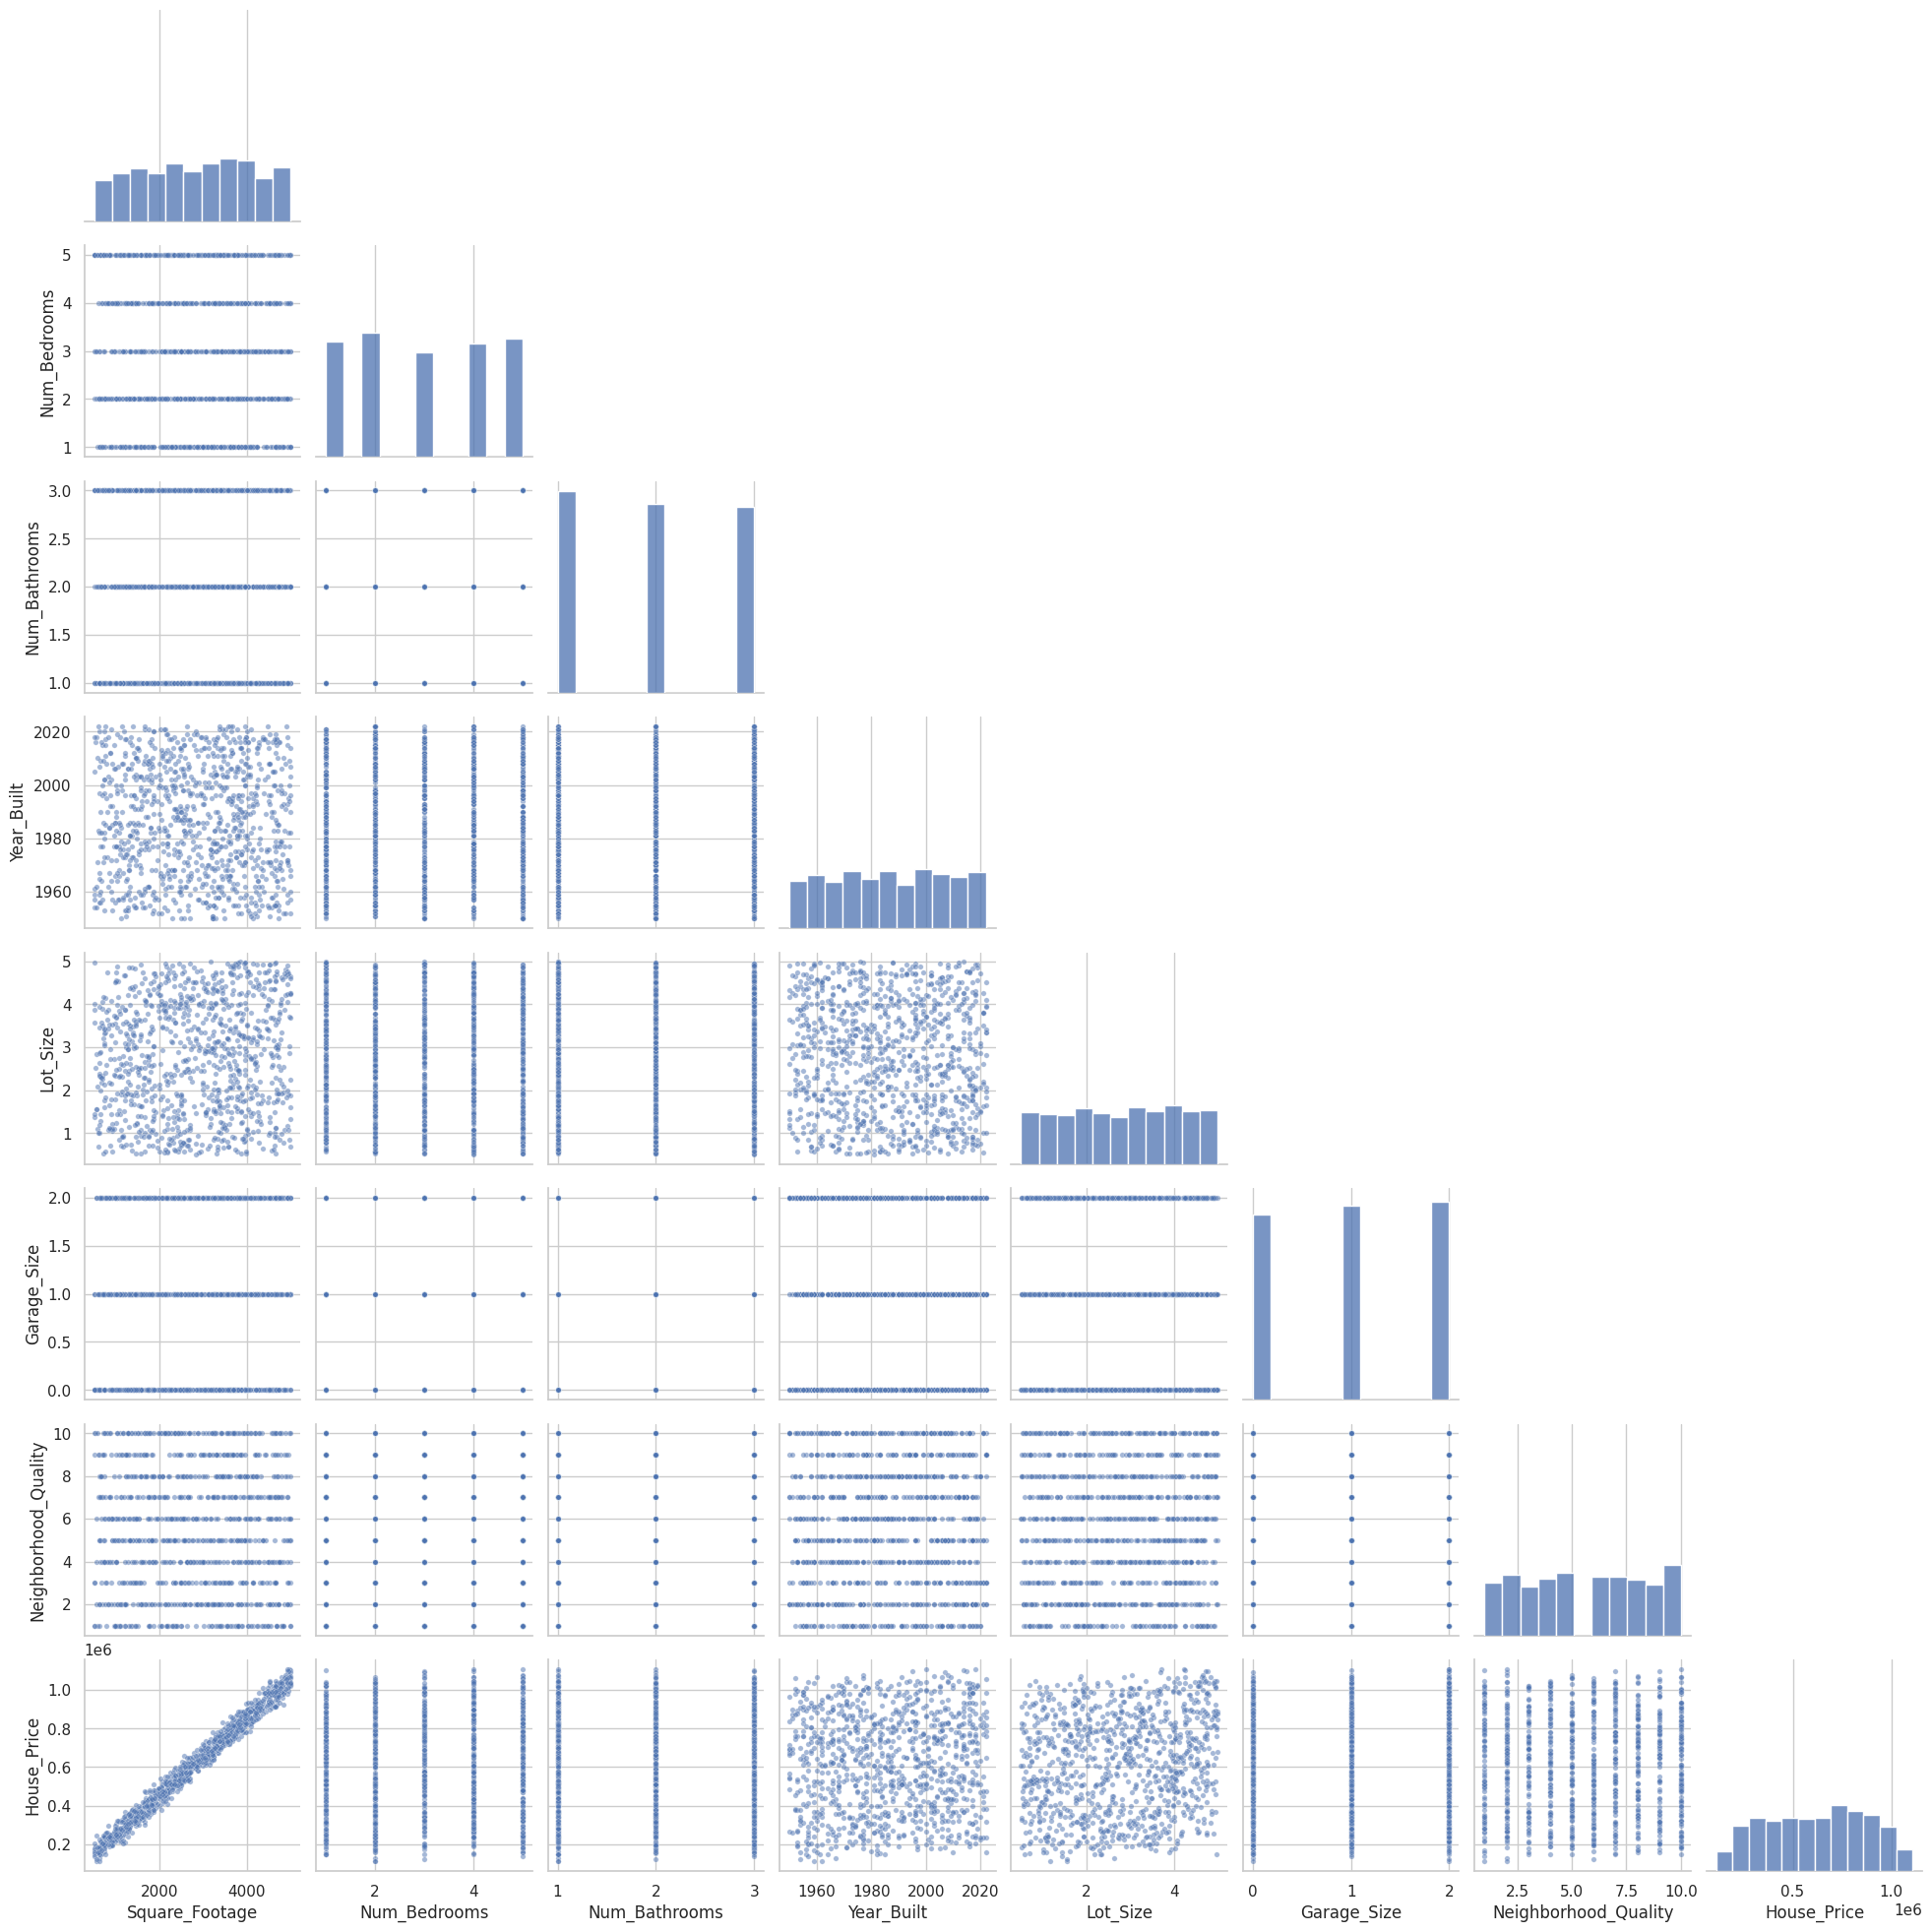

In [12]:
sns.pairplot(df, corner=True, plot_kws={"alpha": 0.5, "s": 15})
plt.show()





## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

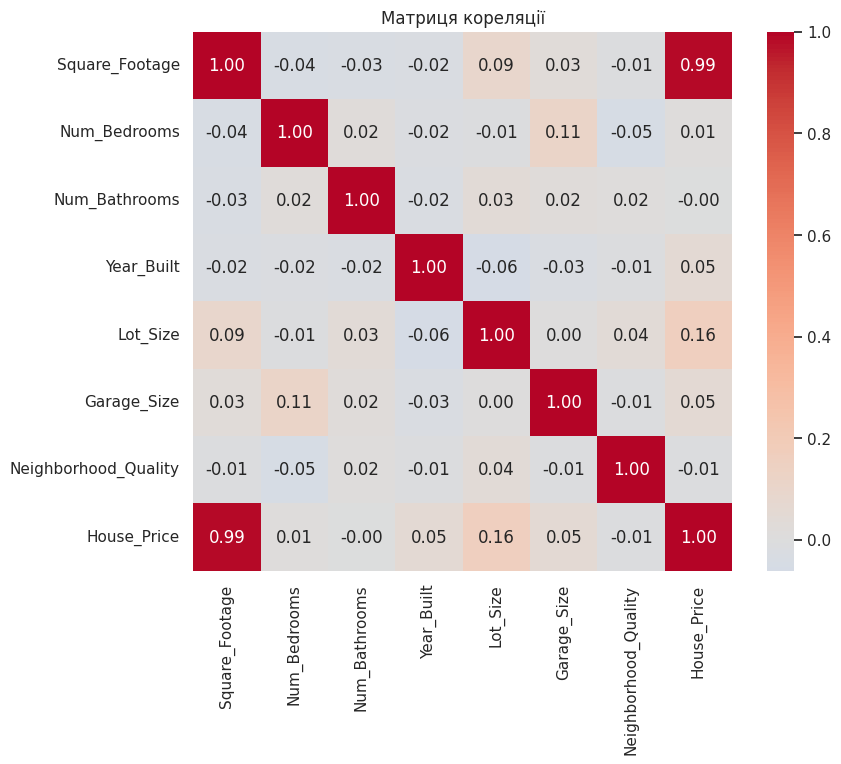

In [13]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Матриця кореляції")
plt.show()





### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [14]:
corr_target = (
    df.corr(numeric_only=True)["House_Price"]
    .drop("House_Price")
    .sort_values(ascending=False)
)
corr_target




,House_Price
Square_Footage,0.991
Lot_Size,0.160
Garage_Size,0.052
Year_Built,0.052
Num_Bedrooms,0.015
Num_Bathrooms,-0.002
Neighborhood_Quality,-0.008


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error





### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [16]:
X = df.drop(columns=["House_Price"])
y = df["House_Price"]
print("X:", X.shape, "| y:", y.shape)




X: (1000, 7) | y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)




Train: (800, 7) | Test: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [18]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=42)),
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=1.0, random_state=42)),
    ]),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
list(models)





['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [19]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("R2", ascending=False)
results_df





,R2,MAE,MSE
Model,,,
Linear Regression,0.998,"8,174.584","101,434,798.506"
Lasso,0.998,"8,174.748","101,436,558.180"
Ridge,0.998,"8,241.587","102,480,990.009"
Gradient Boosting,0.997,"12,305.218","224,965,597.845"
Random Forest,0.994,"16,114.290","394,131,747.446"


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

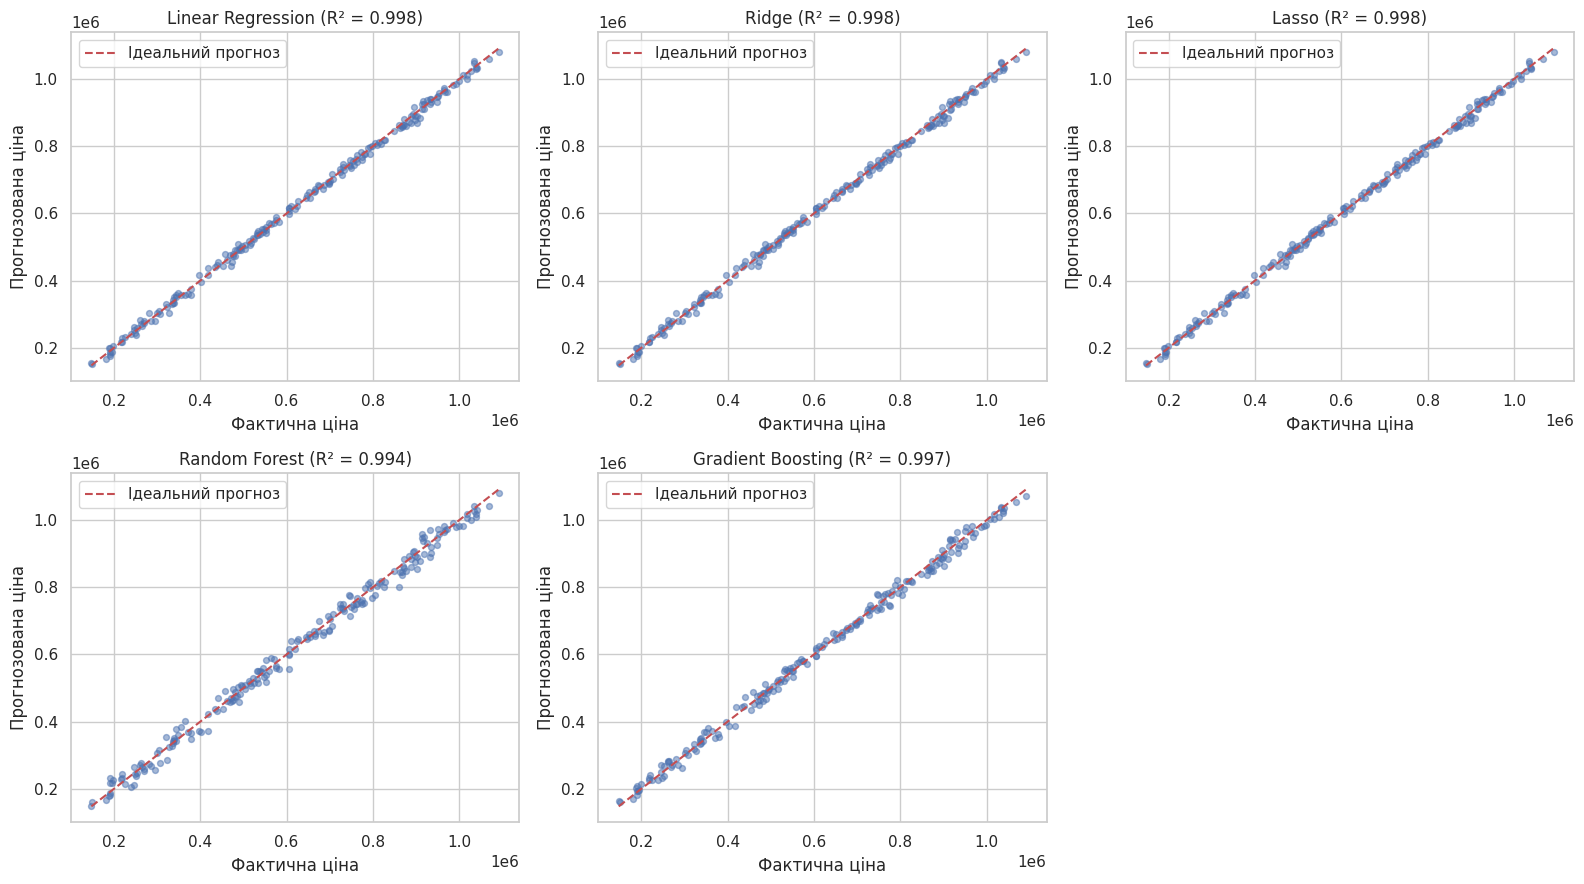

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
lims = [min(y_test.min(), min(p.min() for p in predictions.values())),
        max(y_test.max(), max(p.max() for p in predictions.values()))]

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, s=18)
    ax.plot(lims, lims, "r--", label="Ідеальний прогноз")
    ax.set_title(f"{name} (R² = {r2_score(y_test, y_pred):.3f})")
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend()

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()





## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [21]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2", 1.0],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Найкращі параметри:", grid.best_params_)
print(f"Найкращий CV R²: {grid.best_score_:.4f}")




Fitting 5 folds for each of 108 candidates, totalling 540 fits
Найкращі параметри: {'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 300}
Найкращий CV R²: 0.9920


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [22]:
best_rf = RandomForestRegressor(**grid.best_params_, random_state=42)
best_rf.fit(X_train, y_train)
y_pred_best = best_rf.predict(X_test)

rf_tuned = {
    "R2": r2_score(y_test, y_pred_best),
    "MAE": mean_absolute_error(y_test, y_pred_best),
    "MSE": mean_squared_error(y_test, y_pred_best),
}
rf_tuned





{'R2': 0.9940298846807288, 'MAE': 15930.637875446102, 'MSE': 384826810.1531117}

### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [23]:
rf_compare = pd.DataFrame({
    "Random Forest (базова)": results_df.loc["Random Forest", ["R2", "MAE", "MSE"]],
    "Random Forest (оптимізована)": pd.Series(rf_tuned),
})
rf_compare["Зміна"] = rf_compare["Random Forest (оптимізована)"] - rf_compare["Random Forest (базова)"]
rf_compare





,Random Forest (базова),Random Forest (оптимізована),Зміна
R2,0.994,0.994,0.000
MAE,"16,114.290","15,930.638",-183.652
MSE,"394,131,747.446","384,826,810.153","-9,304,937.293"


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Підбір параметрів дав лише незначне покращення. Найкращі параметри: n_estimators=300, max_features=1.0, max_depth=None, min_samples_split=2. R² зріс з 0.9939 до 0.9940, MAE зменшилась з 16 130 до 15 946, MSE зменшилась приблизно на 9,1 млн. Зміни дуже малі, бо базова модель уже дає R² близько 0.99. Оптимізовану модель використовувати можна, але вона навчається довше, а виграш практично непомітний. До того ж вона все одно поступається лінійним моделям.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [24]:
lr_pred = predictions["Linear Regression"]

pred_table = pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": lr_pred,
})
pred_table["Похибка, %"] = (
    (pred_table["Прогнозована ціна"] - pred_table["Фактична ціна"]).abs()
    / pred_table["Фактична ціна"] * 100
)

pred_table.sample(10, random_state=42).round(2).reset_index(drop=True)





,Фактична ціна,Прогнозована ціна,"Похибка, %"
0,"1,068,538.110","1,059,729.020",0.820
1,"194,353.740","187,868.550",3.340
2,"270,230.640","279,715.820",3.510
3,"986,006.860","981,949.270",0.410
4,"953,339.730","957,382.950",0.420
5,"914,555.750","909,764.270",0.520
6,"746,167.730","742,469.140",0.500
7,"646,766.290","654,445.550",1.190
8,"523,323.070","524,605.440",0.250
9,"1,008,539.160","1,011,343.640",0.280


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

Датасет містить 1000 записів без дублікатів і пропусків. Ціна майже повністю визначається площею (кореляція 0.99), далі йде розмір ділянки (0.16); решта ознак майже не корелює з ціною.

Побудовано п'ять моделей: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting.
Найкраща - Linear Regression (R² = 0.998, MAE ≈ 8 175, MSE ≈ 1.01·10⁸). Ridge і Lasso майже ідентичні, Gradient Boosting (R² = 0.997) і Random Forest (R² = 0.994) трохи гірші, бо залежність ціни від площі практично лінійна.
Підбір гіперпараметрів Random Forest майже не змінив якість (R² 0.9939 - 0.9940, MAE 16 130 - 15 946).
Прогнози дуже точні: медіанна відносна похибка Linear Regression на тесті ≈ 1.2%.
На якість впливають площа, розмір ділянки, розмір вибірки та шум у даних. У реальних умовах додатково стан будинку, локація, інфраструктура й ринкова кон'юнктура. Дані схожі на синтетичні, тому результати завищено порівняно з реальним ринком.